# ML Assignment 2: five classifiers on online shopper sessions
Dataset: UCI Online Shoppers Purchasing Intention (target column `Revenue`).
Run the cells from top to bottom. Each cell is independent code, nothing here needs Colab,
the other repo files, or anything beyond pandas, numpy, scikit-learn, matplotlib and joblib.

In [1]:
# Cell 0: check the libraries work together, and repair them if they do not
# This cell does not import numpy or pandas itself, so it is safe to run first, even when
# the machine has old or mismatched versions installed.
import subprocess
import sys

CHECK = ("import numpy, pandas, matplotlib, joblib, sklearn; import matplotlib.pyplot; "
         "from sklearn.compose import ColumnTransformer; from sklearn.metrics import roc_auc_score; "
         "from sklearn.svm import SVC; from sklearn.model_selection import GridSearchCV; "
         "print(numpy.__version__)")
PACKAGES = ["numpy", "pandas", "matplotlib", "joblib", "scipy", "scikit-learn"]


def libraries_work():
    """Run the imports in a fresh Python, so we see what is really installed on disk."""
    r = subprocess.run([sys.executable, "-c", CHECK], stdout=subprocess.PIPE,
                       stderr=subprocess.PIPE, universal_newlines=True)
    last_line = (r.stderr.strip().splitlines() or [""])[-1]
    return r.returncode == 0, r.stdout.strip(), last_line


def pip_install(extra=()):
    cmd = [sys.executable, "-m", "pip", "install", "--upgrade", "--quiet"] + PACKAGES + list(extra)
    return subprocess.call(cmd) == 0


works, disk_numpy, problem = libraries_work()
if not works:
    print("The installed libraries do not work together yet.")
    print("Problem found:", problem or "(missing library)")
    print("Installing a matching set of versions, this can take a minute or two...")
    if not pip_install() and not pip_install(["--user"]):
        raise RuntimeError("pip could not install the libraries (no internet or no permission?). "
                           "Ask BITS lab support to install numpy, pandas, matplotlib, joblib and scikit-learn.")
    works, disk_numpy, problem = libraries_work()
    if not works:
        raise RuntimeError("Libraries are still not working after the install: " + problem)

# If numpy was already loaded in this kernel (an earlier run), it may be an older version
# than the one on disk. In that case the kernel has to be restarted once.
if "numpy" in sys.modules and sys.modules["numpy"].__version__ != disk_numpy:
    raise RuntimeError(
        "Libraries are now fixed, but this notebook session still holds the old numpy "
        "(%s in memory, %s installed). Click Kernel > Restart, then Kernel > Restart & Run All."
        % (sys.modules["numpy"].__version__, disk_numpy))
print("Libraries are installed and work together (numpy %s). Continue with the next cell." % disk_numpy)

Libraries are installed and work together (numpy 2.5.3). Continue with the next cell.


In [2]:
# Cell 1: imports and settings
import glob
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

# Leave CSV_PATH as None and the notebook looks for the file itself (this folder, a data/ folder,
# Downloads, Desktop, Documents, home). If it still cannot find it, set the full path here, e.g.
# CSV_PATH = "C:/Users/me/Downloads/online_shoppers_intention.csv"
CSV_PATH = None


def find_csv():
    home = os.path.expanduser("~")
    folders = [".", "data", "..", "../data", os.path.join(home, "Downloads"),
               os.path.join(home, "Desktop"), os.path.join(home, "Documents"), home]
    for folder in folders:
        hits = sorted(glob.glob(os.path.join(folder, "*online_shoppers*.csv")))
        if hits:
            return hits[0]
    for dirpath, dirnames, _ in os.walk("."):       # sub-folders of the current folder
        if dirpath.count(os.sep) >= 2:
            dirnames[:] = []
        hits = sorted(glob.glob(os.path.join(dirpath, "*online_shoppers*.csv")))
        if hits:
            return hits[0]
    return None


if CSV_PATH is None:
    CSV_PATH = find_csv()
if CSV_PATH is None:                                 # last resort: download from UCI
    try:
        import io
        import urllib.request
        import zipfile
        url = ("https://archive.ics.uci.edu/static/public/468/"
               "online+shoppers+purchasing+intention+dataset.zip")
        zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=30).read())).extractall(".")
        CSV_PATH = find_csv()
    except Exception:
        pass
if CSV_PATH is None or not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        "Could not find online_shoppers_intention.csv. Copy it next to this notebook "
        "or set CSV_PATH above to its full path, then run this cell again.")

OUT_DIR = "assignment2_outputs"      # models, metrics and test split are saved here
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 42
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("reading", CSV_PATH)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
reading ../data/online_shoppers_intention.csv


In [3]:
# Cell 2: load, clean, look at the data
raw = pd.read_csv(CSV_PATH)
print("raw shape:", raw.shape, "| duplicate rows:", int(raw.duplicated().sum()),
      "| missing values:", int(raw.isna().sum().sum()))

df = raw.drop_duplicates().reset_index(drop=True)
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
print("after dropping duplicates:", df.shape)
print(df["Revenue"].value_counts().rename({0: "no purchase", 1: "purchase"}))
print("share of buyers: %.3f" % df["Revenue"].mean())
print("buying rate when PageValues = 0 :  %.3f" % df.loc[df["PageValues"] == 0, "Revenue"].mean())
print("buying rate when PageValues > 0 :  %.3f" % df.loc[df["PageValues"] > 0, "Revenue"].mean())
df.head()

raw shape: (12330, 18) | duplicate rows: 125 | missing values: 0
after dropping duplicates: (12205, 18)
Revenue
no purchase    10297
purchase        1908
Name: count, dtype: int64
share of buyers: 0.156
buying rate when PageValues = 0 :  0.039
buying rate when PageValues > 0 :  0.563


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


In [4]:
# Cell 3: split, preprocessing and the five models
FEATURES = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay", "Month",
            "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
CATEGORICAL = ["Month", "VisitorType"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

X, y = df[FEATURES], df["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("train:", X_train.shape, "| test:", X_test.shape)

# keep the raw test split as a CSV, the Streamlit app uploads this file
test_df = X_test.copy()
test_df["Revenue"] = y_test.values
test_df.to_csv(os.path.join(OUT_DIR, "test_data.csv"), index=False)


def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])


# name -> (estimator, grid searched with 5-fold cross-validation on the training rows)
MODELS = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [10, 30, 60]}),
    "kNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 41], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
        {"clf__C": [0.5, 1, 5], "clf__gamma": ["scale", 0.01]}),
}


def get_scores(model, data):
    """Score for the positive class, used for AUC and ROC. The SVM has no
    predict_proba here, so it uses its decision function (AUC only needs the ranking)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(data)[:, 1]
    return model.decision_function(data)


def compute_metrics(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_score),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

train: (9764, 17) | test: (2441, 17)


In [5]:
# Cell 4: tune and train every model (about 2 to 5 minutes)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, rows, best_params = {}, [], {}
for name, (est, grid) in MODELS.items():
    t0 = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    try:
        search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
    except Exception:  # some shared servers block parallel workers, so retry on one core
        search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=1).fit(X_train, y_train)
    best = search.best_estimator_
    fitted[name] = best
    best_params[name] = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    m = compute_metrics(y_test, best.predict(X_test), get_scores(best, X_test))
    rows.append(dict({"ML Model Name": name}, **m))
    joblib.dump(best, os.path.join(OUT_DIR, name.lower().replace(" ", "_") + ".pkl"))
    print("%-24s %-45s %.0fs" % (name, search.best_params_, time.time() - t0))

Logistic Regression      {'clf__C': 0.1}                               3s


Decision Tree            {'clf__max_depth': 7, 'clf__min_samples_leaf': 60} 2s


kNN                      {'clf__n_neighbors': 41, 'clf__weights': 'distance'} 2s


Naive Bayes              {'clf__var_smoothing': 0.001}                 0s


Support Vector Machine   {'clf__C': 1, 'clf__gamma': 0.01}             35s


In [6]:
# Cell 5: comparison table (this is the table for the README)
results = pd.DataFrame(rows).set_index("ML Model Name")
results.round(4).to_csv(os.path.join(OUT_DIR, "metrics.csv"))
print("always answering 'no purchase' would score %.4f accuracy" % (1 - y_test.mean()))
results.round(4)

always answering 'no purchase' would score 0.8435 accuracy


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8521,0.9110,0.5181,0.7880,0.6251,0.5562
Decision Tree,0.8562,0.9252,0.5255,0.8351,0.6451,0.5844
kNN,0.8775,0.8739,0.7943,0.2932,0.4283,0.4347
Naive Bayes,0.7218,0.8277,0.3370,0.8037,0.4749,0.3834
Support Vector Machine,0.8759,0.9143,0.5795,0.7539,0.6553,0.5887


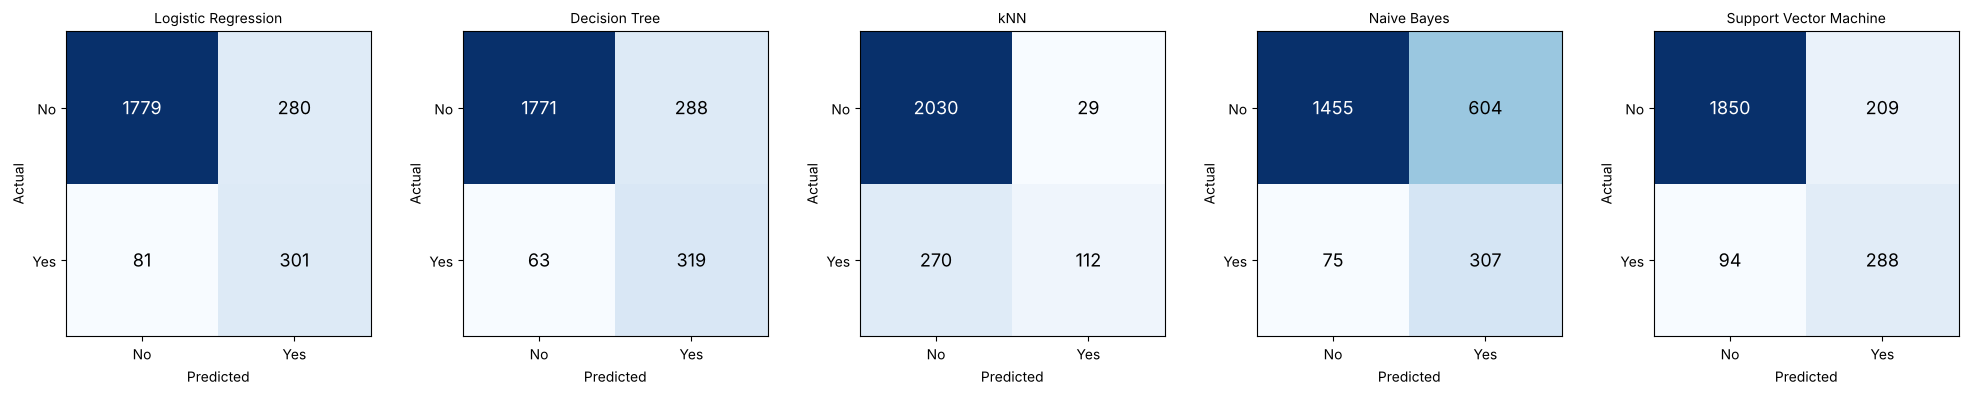

In [7]:
# Cell 6: confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, mdl) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, mdl.predict(X_test), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No", "Yes"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["No", "Yes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

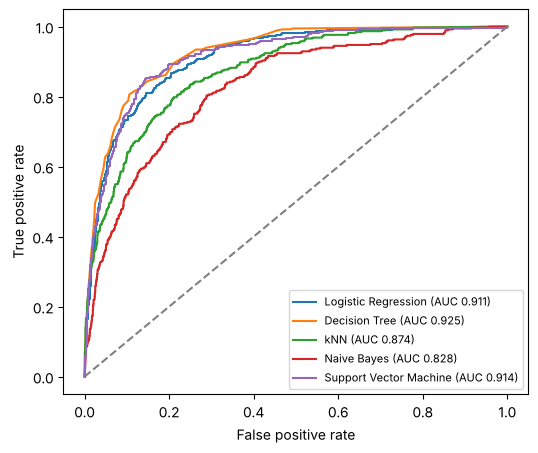

In [8]:
# Cell 7: ROC curves
plt.figure(figsize=(6, 5))
for name, mdl in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, get_scores(mdl, X_test))
    plt.plot(fpr, tpr, label="%s (AUC %.3f)" % (name, results.loc[name, "AUC"]))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.legend(fontsize=8, loc="lower right")
plt.show()

In [9]:
# Cell 8: save the tuned settings and list what was written
pd.Series(best_params).to_json(os.path.join(OUT_DIR, "best_params.json"))
print("saved to", os.path.abspath(OUT_DIR))
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

saved to /tmp/claude-0/-home-claude/e2d065b4-577b-58cf-bbd8-a482fd6fae09/scratchpad/repo/model/assignment2_outputs
   best_params.json
   decision_tree.pkl
   knn.pkl
   logistic_regression.pkl
   metrics.csv
   naive_bayes.pkl
   support_vector_machine.pkl
   test_data.csv
